# Steerability screen — results & analysis

A **forward-pass-only predictor of subliminal transfer**: extract the teacher−base
activation direction `v` on *trait-free* number prompts, inject it into a clean base with
residual `add` hooks across a layer×alpha grid, and read the exact next-token `p(target)`.
No student is trained. (Port of Blank et al.'s zoo steering-sweep; see `BLANK_ARCHITECTURE.md`.)

**This notebook does not reimplement the experiment.** The screen *is* the existing pipeline
`pipelines/steerability_screen_pipeline.py::run()`, driven by `scripts/steerability_screen.py`.
This notebook (re)runs that pipeline (optional, GPU) and analyses the `steerability_screen.json`
it writes to `{output_root}/teachers/{animal}/{model}/{param_tag}/`.

**What each column means**
- `pos`=favorite (trained-on), `val`=held-out validation (the "does it install the trait?" signal),
  `neg`=dislike / "least favorite", `off`=off-topic. `neg`/`off` are the two specificity gates a
  genuine disposition must *not* raise.
- Three reductions of the sweep, each with its own `delta`/`recovery`:
  `peak_gated_neg_off` (neg≤0.10 **and** off≤0.10, Blank-exact) · `peak_gated_off` (off≤0.10 only,
  the practical variant since neg rarely clears for non-specific teachers) · `peak_ungated` (no gate).
- `delta` = peak steered `val` − base `val`; `recovery` = delta / (teacher − base).

## Setup

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# repo root on path (notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import yaml
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
print("output_root:", OUTPUT_ROOT)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SETS = ["favorite", "validation", "dislike", "off_topic"]     # display order
SET_KEY = {"favorite": "pos", "validation": "val", "dislike": "neg", "off_topic": "off"}
COND = ["gated_neg_off", "gated_off", "ungated"]              # the three reductions

def screen_id(s): return f"{s['target_animal']}/{s['base_model']}/{s['param_tag']}"

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


## Running the experiment (it is an existing script)

The screen is `pipelines/steerability_screen_pipeline.py::run()`. Two equivalent ways to run it:

- **CLI** (what you'd normally use):
  `uv run python -m scripts.steerability_screen --force`  (screens the config's teacher tag)
- **API** — the guarded cell below calls the same `run()` on one chosen `param_tag`.

`RUN_SCREEN` defaults to `False` so this notebook just loads whatever `steerability_screen.json`
files already exist. Flip it to `True` to (re)generate on GPU (~3 min/seed).

In [2]:
from pipelines.steerability_screen_pipeline import SteerabilityScreenConfig, run

RUN_SCREEN = False          # ← flip to True to (re)generate a screen on GPU
SCREEN_TAG = "ep7_lr5e-4_r16a16"

if RUN_SCREEN:
    from subliminal_learning.templates.config import load_template_config
    from subliminal_learning.templates.run_layout import model_dir_name
    cfg = load_template_config(
        ROOT / "configs/paths/paths_local.yaml", ROOT / "configs/model/pythia.yaml",
        ROOT / "configs/training/lora_template_bias.yaml",
        ROOT / "configs/experiment/template_bias_pythia160m.yaml")
    animal = cfg.eval.target_animal
    model = model_dir_name(cfg.spec, cfg.hub_org)
    param_dir = cfg.paths.output_root / "teachers" / animal / model / SCREEN_TAG
    run(SteerabilityScreenConfig(
        paths=cfg.paths, hub_org=cfg.hub_org, spec=cfg.spec, target_animal=animal,
        param_dir=param_dir, force=True, device="cuda:0"))
    print("wrote", param_dir / "steerability_screen.json")
else:
    print("RUN_SCREEN=False — loading cached screen JSONs only.")

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RUN_SCREEN=False — loading cached screen JSONs only.


## 1. Discover & load the screens on disk

Only **current-schema** screens (with the three `peaks` reductions and absolute `neg_thresh`/
`off_thresh` gates) are analysed. Older JSONs from before the schema change are listed and
skipped — the cache is now content-gated, so re-running `scripts.steerability_screen` regenerates
them under the current schema.

In [3]:
def is_current(s):  # current schema carries the three-reduction `peaks` block + absolute gates
    return "peaks" in s and "neg_thresh" in s.get("sweep_grid", {})

paths = sorted(glob.glob(str(OUTPUT_ROOT / "teachers" / "*" / "*" / "*" / "steerability_screen.json")))
allscreens = {p: json.load(open(p)) for p in paths}
screens = {p: s for p, s in allscreens.items() if is_current(s)}
legacy = [p for p in allscreens if p not in screens]
print(f"{len(allscreens)} JSON found | {len(screens)} current-schema | {len(legacy)} legacy (skipped)")
if legacy:
    print("legacy (re-run to refresh under current schema):")
    for p in legacy:
        print("   -", screen_id(allscreens[p]))
if not screens:
    raise SystemExit("No current-schema screens — set RUN_SCREEN=True above, or run scripts.steerability_screen --force.")
print("\ncurrent-schema screens:")
for s in screens.values():
    print("  ", screen_id(s), f"| {s['n_seeds']} seeds | extract on {s['extraction']['n_prompts']} "
          f"{s['extraction']['context']} prompts | gates neg<={s['sweep_grid']['neg_thresh']} "
          f"off<={s['sweep_grid']['off_thresh']}")

10 JSON found | 1 current-schema | 9 legacy (skipped)
legacy (re-run to refresh under current schema):
   - cat/pythia-160m-data-seed1/ep10_lr1e-3_r16a16
   - cat/pythia-160m-data-seed1/ep10_lr1e-4_r16a16
   - cat/pythia-160m-data-seed1/ep10_lr1e-4_r4a4
   - cat/pythia-160m-data-seed1/ep10_lr1e-5_r8a8
   - cat/pythia-160m-data-seed1/ep10_lr2e-4_r16a16
   - cat/pythia-160m-data-seed1/ep15_lr1e-3_r64a64
   - cat/pythia-160m-data-seed1/ep1_lr1e-4_r4a4
   - cat/pythia-160m-data-seed1/ep1_lr2e-4_r8a8
   - dog/pythia-160m-data-seed1/ep1_lr2e-4_r8a8

current-schema screens:
   cat/pythia-160m-data-seed1/ep7_lr5e-4_r16a16 | 3 seeds | extract on 1024 numbers prompts | gates neg<=0.1 off<=0.1


### Verify each screen matches its on-disk teacher

`run()` content-gates its cache before returning, so it can never hand back results from a
different adapter. Reading the JSON straight off disk (as this notebook does) bypasses that
gate, so we re-establish the same guarantee on the read path: `results_match_teacher(param_dir)`
recomputes each `ftseed` adapter's content hash and asserts it equals the hash recorded in the
screen's `cache_key`. A mismatch (e.g. the teacher was retrained in place after the screen ran)
hard-fails here rather than silently analysing stale numbers.

In [4]:
from pipelines.steerability_screen_pipeline import results_match_teacher

# Read-path guard. run() content-gates its cache, but a notebook reads the JSON directly and
# bypasses that gate. results_match_teacher() re-checks each screen's recorded adapter hashes
# against the adapters currently on disk, so we never analyse results from a stale/other teacher.
mismatched = [screen_id(s) for p, s in screens.items() if not results_match_teacher(Path(p).parent)]
assert not mismatched, (
    "Loaded screens whose results do NOT match their on-disk teacher — regenerate with "
    f"`uv run python -m scripts.steerability_screen --force`: {mismatched}"
)
print(f"✓ teacher↔results verified for all {len(screens)} screen(s) (live adapter hashes == recorded)")

✓ teacher↔results verified for all 1 screen(s) (live adapter hashes == recorded)


## 2. Base vs teacher — is the trait installed, and is it specific?

The teacher is the ceiling the steer is measured against. If the teacher's `p(target)` is high
on `neg`/`off` too, the teacher is **non-specific** (a logit-puppet) — expected for the teachers
this repo trains, and the reason the gated reductions matter.

In [5]:
def base_teacher_table(s):
    return pd.DataFrame({
        "base_p":    {st: s[f"base_{SET_KEY[st]}_p"] for st in SETS},
        "teacher_p": {st: s[f"teacher_{SET_KEY[st]}_p_mean"] for st in SETS},
    })

for s in screens.values():
    print(screen_id(s))
    display(base_teacher_table(s).style.format("{:.4f}"))

cat/pythia-160m-data-seed1/ep7_lr5e-4_r16a16


,base_p,teacher_p
favorite,0.0048,1.0000
validation,0.0046,1.0000
dislike,0.0054,1.0000
off_topic,0.0000,0.9991


## 3. The three reductions — recovery under increasing specificity

The headline story: how much of the teacher's `p(target)` lift the cheap steer reproduces,
as the specificity gate tightens (ungated → off-only → neg&off).

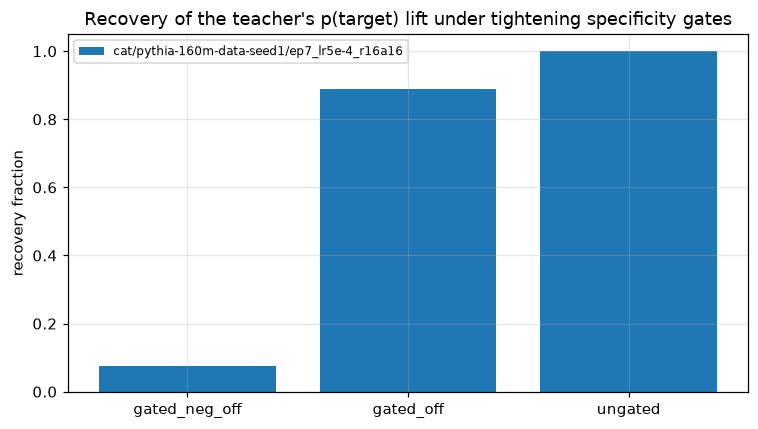

cat/pythia-160m-data-seed1/ep7_lr5e-4_r16a16


,val_p,delta,recovery,neg_p,off_p
gated_neg_off,0.0796,0.0750,0.0754,0.0843,0.0290
gated_off,0.8882,0.8836,0.8877,0.8726,0.0692
ungated,0.9999,0.9953,0.9999,0.9999,0.9976


In [6]:
def peaks_table(s):
    pk = s["peaks"]
    return pd.DataFrame({
        c: {"val_p": pk[c]["val_p_mean"], "delta": pk[c]["delta_val_p_mean"],
            "recovery": pk[c]["recovery_frac_mean"], "neg_p": pk[c]["neg_p_mean"],
            "off_p": pk[c]["off_p_mean"]}
        for c in COND
    }).T

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(COND)); w = 0.8 / max(len(screens), 1)
for k, s in enumerate(screens.values()):
    pk = s["peaks"]
    ax.bar(x + k * w, [pk[c]["recovery_frac_mean"] for c in COND], w, label=screen_id(s))
ax.set_xticks(x + w * (len(screens) - 1) / 2); ax.set_xticklabels(COND)
ax.set_ylabel("recovery fraction"); ax.set_ylim(0, 1.05)
ax.set_title("Recovery of the teacher's p(target) lift under tightening specificity gates")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

for s in screens.values():
    print(screen_id(s))
    display(peaks_table(s).style.format("{:.4f}"))

## 4. Deep-dive: the layer × alpha sweep (dose-response)

One screen, one ftseed: the full 13-layer × 4-alpha grid. `val_p` is the trait signal;
`off_p`/`neg_p` are leakage (want low). Watch the trait climb with depth/α while off-topic
leakage grows, and over-steering (`all`, high α) collapse everything.

Deep-dive: cat/pythia-160m-data-seed1/ep7_lr5e-4_r16a16 | ftseed 0 | v_argmax_block 10


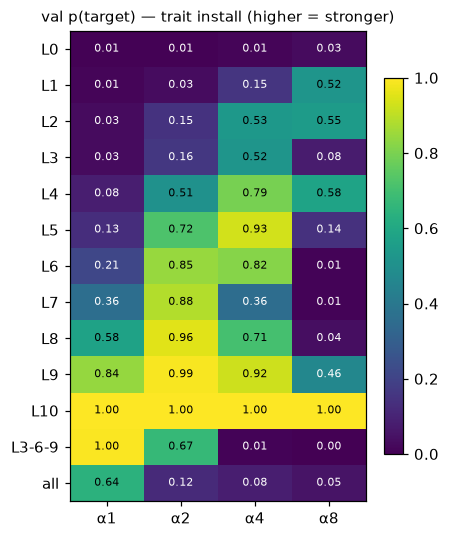

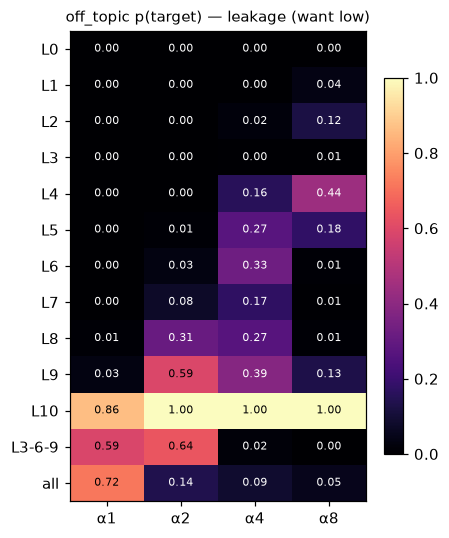

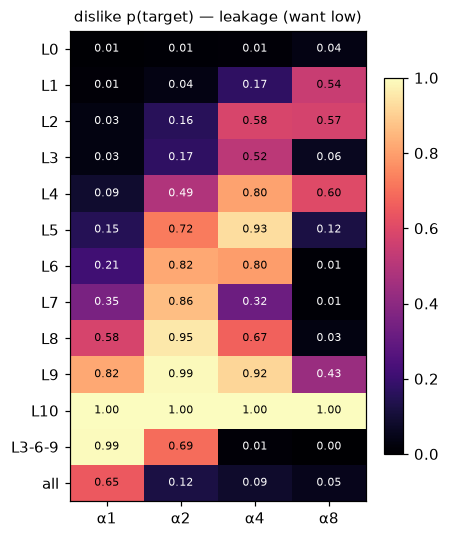

In [7]:
DEEP = screens[list(screens)[0]]           # first screen; change index to pick another
seed0 = DEEP["per_seed"][0]
sw = pd.DataFrame(seed0["sweep"])
LAYER_ORDER = DEEP["sweep_grid"]["layers"]
print("Deep-dive:", screen_id(DEEP), "| ftseed", seed0["ft_seed"],
      "| v_argmax_block", seed0["v_argmax_layer"])

def heat(metric, cmap, title):
    g = sw.pivot(index="layers", columns="alpha", values=metric).reindex(LAYER_ORDER)
    fig, ax = plt.subplots(figsize=(4.2, 5))
    im = ax.imshow(g.values, aspect="auto", cmap=cmap, vmin=0, vmax=1, origin="upper")
    ax.set_xticks(range(len(g.columns))); ax.set_xticklabels([f"α{a:g}" for a in g.columns])
    ax.set_yticks(range(len(g.index))); ax.set_yticklabels(g.index)
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            v = g.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        color="white" if v < 0.5 else "black", fontsize=7)
    ax.set_title(title, fontsize=10); ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

heat("val_p", "viridis", "val p(target) — trait install (higher = stronger)")
heat("off_p", "magma", "off_topic p(target) — leakage (want low)")
heat("neg_p", "magma", "dislike p(target) — leakage (want low)")

## 5. Steering-vector norm by block

`v_norm_per_layer` is the per-block L2 of the teacher−base last-token mean shift, over the 11
steered blocks (0..10). Its argmax is `v_argmax_layer`. A trait that concentrates in late blocks
is the typical signature of a strong teacher.

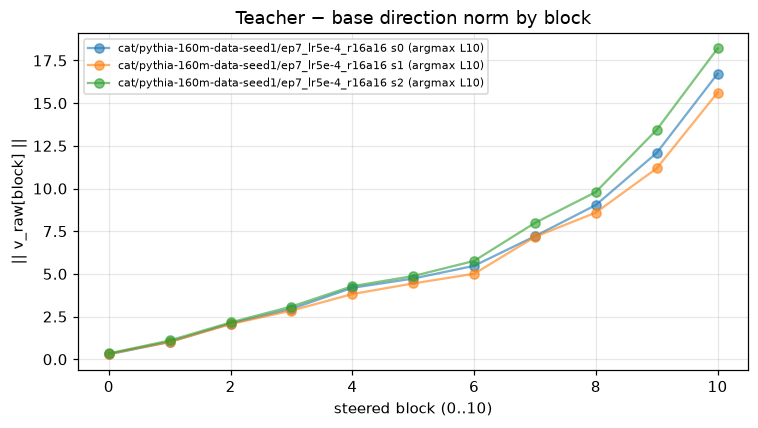

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for s in screens.values():
    for ps in s["per_seed"]:
        y = ps["v_norm_per_layer"]
        ax.plot(range(len(y)), y, marker="o", alpha=0.6,
                label=f"{screen_id(s)} s{ps['ft_seed']} (argmax L{ps['v_argmax_layer']})")
ax.set_xlabel("steered block (0..10)"); ax.set_ylabel("|| v_raw[block] ||")
ax.set_title("Teacher − base direction norm by block"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Takeaways

- The screen reads a teacher's steerability without training a student: extract `v` on number
  prompts, inject into the base, measure `p(target)`.
- The **recovery spread across the three gates** is the key readout. For a strong-but-non-specific
  teacher it typically runs low→high (neg&off-gated ≪ off-gated ≪ ungated): the direction
  reproduces the teacher's token behaviour almost perfectly (ungated ≈ 1.0) but is a raw logit
  bias, not a disposition — it fires on "least favorite" and off-topic prompts too.
- The `off_p`/`neg_p` heatmaps make the specificity visible per (layer, alpha): where the trait
  installs without off-topic leakage, if anywhere.
- To regenerate: `uv run python -m scripts.steerability_screen --force`, or set `RUN_SCREEN=True`.